## 1. Enter the distance matrix

The distances below are read from the table in the class notes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cities = ["A", "B", "C", "D", "E"]

distance = np.array([
    [0,  2,  9, 10,  7],
    [2,  0,  6,  4,  3],
    [9,  6,  0,  8,  9],
    [10, 4,  8,  0,  5],
    [7,  3,  9,  5,  0]
], dtype=float)

# Heuristic desirability: shorter distance means higher desirability
eta = np.zeros_like(distance)
for i in range(len(cities)):
    for j in range(len(cities)):
        if i != j:
            eta[i, j] = 1 / distance[i, j]

# Initial pheromone on every valid edge
tau = np.ones_like(distance)
np.fill_diagonal(tau, 0)

print("Distance matrix:")
display(pd.DataFrame(distance, index=cities, columns=cities))

print("Heuristic matrix eta = 1 / distance:")
display(pd.DataFrame(np.round(eta, 4), index=cities, columns=cities))

Distance matrix:


,A,B,C,D,E
A,0.0,2.0,9.0,10.0,7.0
B,2.0,0.0,6.0,4.0,3.0
C,9.0,6.0,0.0,8.0,9.0
D,10.0,4.0,8.0,0.0,5.0
E,7.0,3.0,9.0,5.0,0.0


Heuristic matrix eta = 1 / distance:


,A,B,C,D,E
A,0.0000,0.5000,0.1111,0.100,0.1429
B,0.5000,0.0000,0.1667,0.250,0.3333
C,0.1111,0.1667,0.0000,0.125,0.1111
D,0.1000,0.2500,0.1250,0.000,0.2000
E,0.1429,0.3333,0.1111,0.200,0.0000


## 2. Set parameters and calculate transition probabilities

The denominator includes only cities that the ant has not visited yet. The function below calculates the probabilities from the current city.

In [2]:
alpha = 1
beta = 1
rho = 0.5
Q = 100
ant_starts = ["A", "B", "C"]

def transition_probabilities(current_city, unvisited, tau, eta):
    current = cities.index(current_city)

    weights = []
    for city in unvisited:
        j = cities.index(city)
        weight = (tau[current, j] ** alpha) * (eta[current, j] ** beta)
        weights.append(weight)

    total = sum(weights)
    probabilities = [weight / total for weight in weights]

    return pd.DataFrame({
        "Candidate city": unvisited,
        "Pheromone tau": [tau[current, cities.index(city)] for city in unvisited],
        "Heuristic eta": [eta[current, cities.index(city)] for city in unvisited],
        "Weight tau^alpha * eta^beta": weights,
        "Probability": probabilities
    })

# Example from ant A's starting position
print("First choice probabilities for an ant starting at A:")
display(transition_probabilities("A", ["B", "C", "D", "E"], tau, eta).round(4))

First choice probabilities for an ant starting at A:


,Candidate city,Pheromone tau,Heuristic eta,Weight tau^alpha * eta^beta,Probability
0,B,1.0,0.5000,0.5000,0.5855
1,C,1.0,0.1111,0.1111,0.1301
2,D,1.0,0.1000,0.1000,0.1171
3,E,1.0,0.1429,0.1429,0.1673


## 3. Construct a tour for each ant

At each step, the ant randomly selects an unvisited city according to the calculated probabilities. Once all cities have been visited, it returns to its starting city.

A fixed random seed is used so that your run is reproducible.

In [3]:
def construct_tour(start_city, tau, eta, rng):
    tour = [start_city]
    unvisited = [city for city in cities if city != start_city]

    while unvisited:
        current = tour[-1]
        prob_table = transition_probabilities(current, unvisited, tau, eta)
        probabilities = prob_table["Probability"].to_numpy()

        next_city = rng.choice(unvisited, p=probabilities)
        tour.append(next_city)
        unvisited.remove(next_city)

    return tour

def calculate_tour_length(tour):
    closed_tour = tour + [tour[0]]
    total_distance = 0

    for i in range(len(closed_tour) - 1):
        a = cities.index(closed_tour[i])
        b = cities.index(closed_tour[i + 1])
        total_distance += distance[a, b]

    return total_distance

rng = np.random.default_rng(42)

tours = []
tour_lengths = []

for start in ant_starts:
    tour = construct_tour(start, tau, eta, rng)
    length = calculate_tour_length(tour)
    tours.append(tour)
    tour_lengths.append(length)

tour_results = pd.DataFrame({
    "Ant": [1, 2, 3],
    "Starting city": ant_starts,
    "Tour": [" -> ".join(tour + [tour[0]]) for tour in tours],
    "Tour length L": tour_lengths,
    "Pheromone deposit Q/L": [Q / length for length in tour_lengths]
})

display(tour_results.round(4))

,Ant,Starting city,Tour,Tour length L,Pheromone deposit Q/L
0,1,A,A -> D -> C -> E -> B -> A,32.0,3.1250
1,2,B,B -> A -> E -> D -> C -> B,28.0,3.5714
2,3,C,C -> A -> B -> D -> E -> C,29.0,3.4483


## 4. Pheromone update

First, pheromone evaporation is applied:

\[
(1-\rho)\tau_{ij}=0.5\tau_{ij}.
\]

Then each ant deposits \(Q/L_k\) on every edge in its tour. Because the problem is symmetric, the update is applied to both \((i,j)\) and \((j,i)\).

In [4]:
# Evaporate old pheromone
tau_new = (1 - rho) * tau

# Add pheromone deposited by each ant on the edges in its closed tour
for tour, length in zip(tours, tour_lengths):
    deposit = Q / length
    closed_tour = tour + [tour[0]]

    for i in range(len(closed_tour) - 1):
        a = cities.index(closed_tour[i])
        b = cities.index(closed_tour[i + 1])

        tau_new[a, b] += deposit
        tau_new[b, a] += deposit  # Symmetric edge

np.fill_diagonal(tau_new, 0)

print("Pheromone matrix after one iteration:")
display(pd.DataFrame(np.round(tau_new, 4), index=cities, columns=cities))

Pheromone matrix after one iteration:


,A,B,C,D,E
A,0.0000,10.6447,3.9483,3.6250,4.0714
B,10.6447,0.0000,4.0714,3.9483,3.6250
C,3.9483,4.0714,0.0000,7.1964,7.0733
D,3.6250,3.9483,7.1964,0.0000,7.5197
E,4.0714,3.6250,7.0733,7.5197,0.0000


## 5. Repeat ACO for multiple iterations

The same steps are repeated: construct tours, measure their lengths, evaporate pheromone, and add deposits. The best tour found is retained. The stopping condition here is a fixed number of iterations.

In [5]:
n_iterations = 50
rng = np.random.default_rng(42)

tau_run = np.ones_like(distance)
np.fill_diagonal(tau_run, 0)

best_tour = None
best_length = float("inf")
best_history = []

for iteration in range(n_iterations):
    iteration_tours = []
    iteration_lengths = []

    # Step 1: construct one solution per ant
    for start in ant_starts:
        tour = construct_tour(start, tau_run, eta, rng)
        length = calculate_tour_length(tour)

        iteration_tours.append(tour)
        iteration_lengths.append(length)

        if length < best_length:
            best_length = length
            best_tour = tour[:]

    # Step 2: evaporate pheromone
    tau_run = (1 - rho) * tau_run

    # Step 3: reinforce edges used by each ant
    for tour, length in zip(iteration_tours, iteration_lengths):
        deposit = Q / length
        closed_tour = tour + [tour[0]]

        for i in range(len(closed_tour) - 1):
            a = cities.index(closed_tour[i])
            b = cities.index(closed_tour[i + 1])
            tau_run[a, b] += deposit
            tau_run[b, a] += deposit

    np.fill_diagonal(tau_run, 0)
    best_history.append(best_length)

print("Best tour found:", " -> ".join(best_tour + [best_tour[0]]))
print("Best tour length:", best_length)

Best tour found: A -> B -> E -> D -> C -> A
Best tour length: 27.0


## 6. Convergence plot

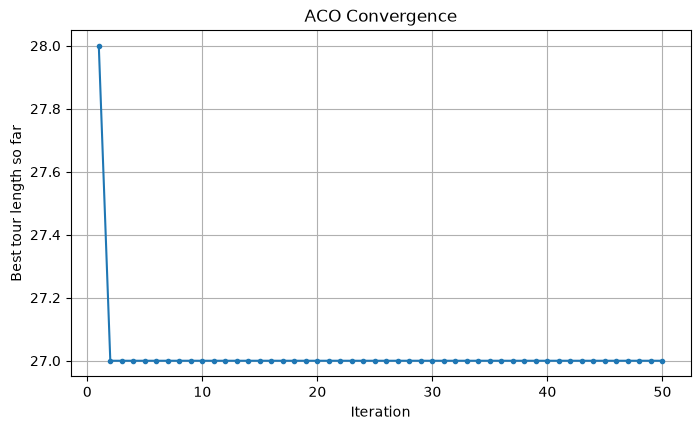

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, n_iterations + 1), best_history, marker="o", markersize=3)
plt.xlabel("Iteration")
plt.ylabel("Best tour length so far")
plt.title("ACO Convergence")
plt.grid(True)
plt.show()

## 7. Optional: reproduce the example tours written in the notes

The notes appear to use these illustrative tours for the pheromone arithmetic:
- Ant 1: A → B → E → D → C → A, length \(2+3+5+8+9=27\)
- Ant 2: B → A → E → D → C → B, length \(2+7+5+8+6=28\)
- Ant 3: C → B → A → E → D → C, length \(6+2+7+5+8=28\)

This cell calculates the pheromone deposits for those tours exactly, regardless of the random tours produced by the algorithm above.

In [7]:
example_tours = [
    ["A", "B", "E", "D", "C"],
    ["B", "A", "E", "D", "C"],
    ["C", "B", "A", "E", "D"]
]

example_lengths = [calculate_tour_length(tour) for tour in example_tours]

example_table = pd.DataFrame({
    "Ant": [1, 2, 3],
    "Tour": [" -> ".join(tour + [tour[0]]) for tour in example_tours],
    "Tour length": example_lengths,
    "Deposit Q/L": [Q / length for length in example_lengths]
})
display(example_table.round(4))

tau_example = np.ones_like(distance)
np.fill_diagonal(tau_example, 0)
tau_example = (1 - rho) * tau_example

for tour, length in zip(example_tours, example_lengths):
    deposit = Q / length
    closed_tour = tour + [tour[0]]
    for i in range(len(closed_tour) - 1):
        a = cities.index(closed_tour[i])
        b = cities.index(closed_tour[i + 1])
        tau_example[a, b] += deposit
        tau_example[b, a] += deposit

np.fill_diagonal(tau_example, 0)
print("Updated pheromone matrix for the example tours:")
display(pd.DataFrame(np.round(tau_example, 4), index=cities, columns=cities))

,Ant,Tour,Tour length,Deposit Q/L
0,1,A -> B -> E -> D -> C -> A,27.0,3.7037
1,2,B -> A -> E -> D -> C -> B,28.0,3.5714
2,3,C -> B -> A -> E -> D -> C,28.0,3.5714


Updated pheromone matrix for the example tours:


,A,B,C,D,E
A,0.0000,11.3466,4.2037,0.5000,7.6429
B,11.3466,0.0000,7.6429,0.5000,4.2037
C,4.2037,7.6429,0.0000,11.3466,0.5000
D,0.5000,0.5000,11.3466,0.0000,11.3466
E,7.6429,4.2037,0.5000,11.3466,0.0000


## Short conclusion

ACO constructs tours using pheromone and heuristic information. The heuristic \(\eta_{ij}=1/d_{ij}\) favors shorter edges. After each iteration, pheromone evaporates by the factor \(1-\rho\), and ants deposit \(Q/L_k\) on the edges they used. Repeating these steps makes edges belonging to shorter tours more attractive. Since the algorithm is stochastic, the exact tour can vary between runs.